# Single-stock risk report
Prabhutosh Kumar · adjusted-price analysis · daily log returns

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "AMZN"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/prabhu/PythonProjects/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Prabhutosh_Kumar/data/data.db"


In [3]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analysis import (load_stock, calculate_returns, calculate_volatility,
                      calculate_max_drawdown, calculate_sharpe_ratio, metrics, plot_report)
frame = load_stock(db_path, ticker, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(frame)} trading days")
print(f"Actual observations: {frame.index.min().date()} to {frame.index.max().date()}")
display(frame.head())
display(frame.tail())
if len(frame) < 21:
    print("Insufficient history for 20 returns: rolling volatility is unavailable.")
if len(frame) < 50:
    print("Insufficient history for a 50-day moving average.")
print("Missing sessions are not filled. Returns span consecutive retained observations; gaps can affect daily-risk estimates.")

AMZN from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29


,open,high,low,close,adj_close,volume,ticker,original_ticker,source_row,repair_flags,extreme_return_review,adjustment_factor
ts,,,,,,,,,,,,
2024-06-03,177.70,178.70,175.92,178.34,178.34,30786640,AMZN,AMZN,30542,,0,1.0
2024-06-04,177.64,179.82,176.44,179.34,179.34,27198388,AMZN,"<a target=""_blank""><span style=""color: blue"">A...",30543,,0,1.0
2024-06-05,180.10,181.50,178.75,181.28,181.28,32116394,AMZN,"<a target=""_blank""><span style=""color: red"">AM...",30545,,0,1.0
2024-06-06,181.75,185.00,181.49,185.00,185.00,31371151,AMZN,"<a target=""_blank""><span style=""font-weight: b...",30546,,0,1.0
2024-06-07,184.90,186.29,183.36,184.30,184.30,28021473,AMZN,AMZN,30547,,0,1.0


,open,high,low,close,adj_close,volume,ticker,original_ticker,source_row,repair_flags,extreme_return_review,adjustment_factor
ts,,,,,,,,,,,,
2024-11-22,198.25,199.26,196.75,197.12,197.12,31530844,AMZN,AMZN,30680,,0,1.0
2024-11-25,199.28,201.95,199.00,201.45,201.45,40685700,AMZN,AMZN,30681,adj_close_from_reference_date_factor,0,1.0
2024-11-26,201.90,208.00,201.79,207.86,207.86,41673737,AMZN,AMZN,30682,adj_close_from_reference_date_factor,0,1.0
2024-11-27,206.98,207.64,205.05,205.74,205.74,28061638,AMZN,AMZN,30683,,0,1.0
2024-11-29,205.83,208.20,204.59,207.89,207.89,24892447,AMZN,AMZN,30684,,0,1.0


Missing sessions are not filled. Returns span consecutive retained observations; gaps can affect daily-risk estimates.


## Risk measures
All report returns use adjusted close. Rolling volatility uses 20 log returns and sample standard deviation, annualized by √252. Warm-up gaps are preserved. Sharpe uses the course approximation `(mean log return × 252 − 0.02)/(sample std × √252)`; undefined or zero volatility displays N/A. Drawdown can recover; its minimum is maximum drawdown.

Price segments use mean rolling volatility as a retrospective threshold (red above, green at/below, gray unavailable). Comparisons across stocks with different actual histories are descriptive, not like-for-like performance rankings.

,adj_close,log_return,rolling_volatility,drawdown
ts,,,,
2024-11-22,197.12,-0.006372,0.374857,-0.079309
2024-11-25,201.45,0.021729,0.381088,-0.059085
2024-11-26,207.86,0.031324,0.392656,-0.029145
2024-11-27,205.74,-0.010252,0.395331,-0.039047
2024-11-29,207.89,0.010396,0.371299,-0.029005


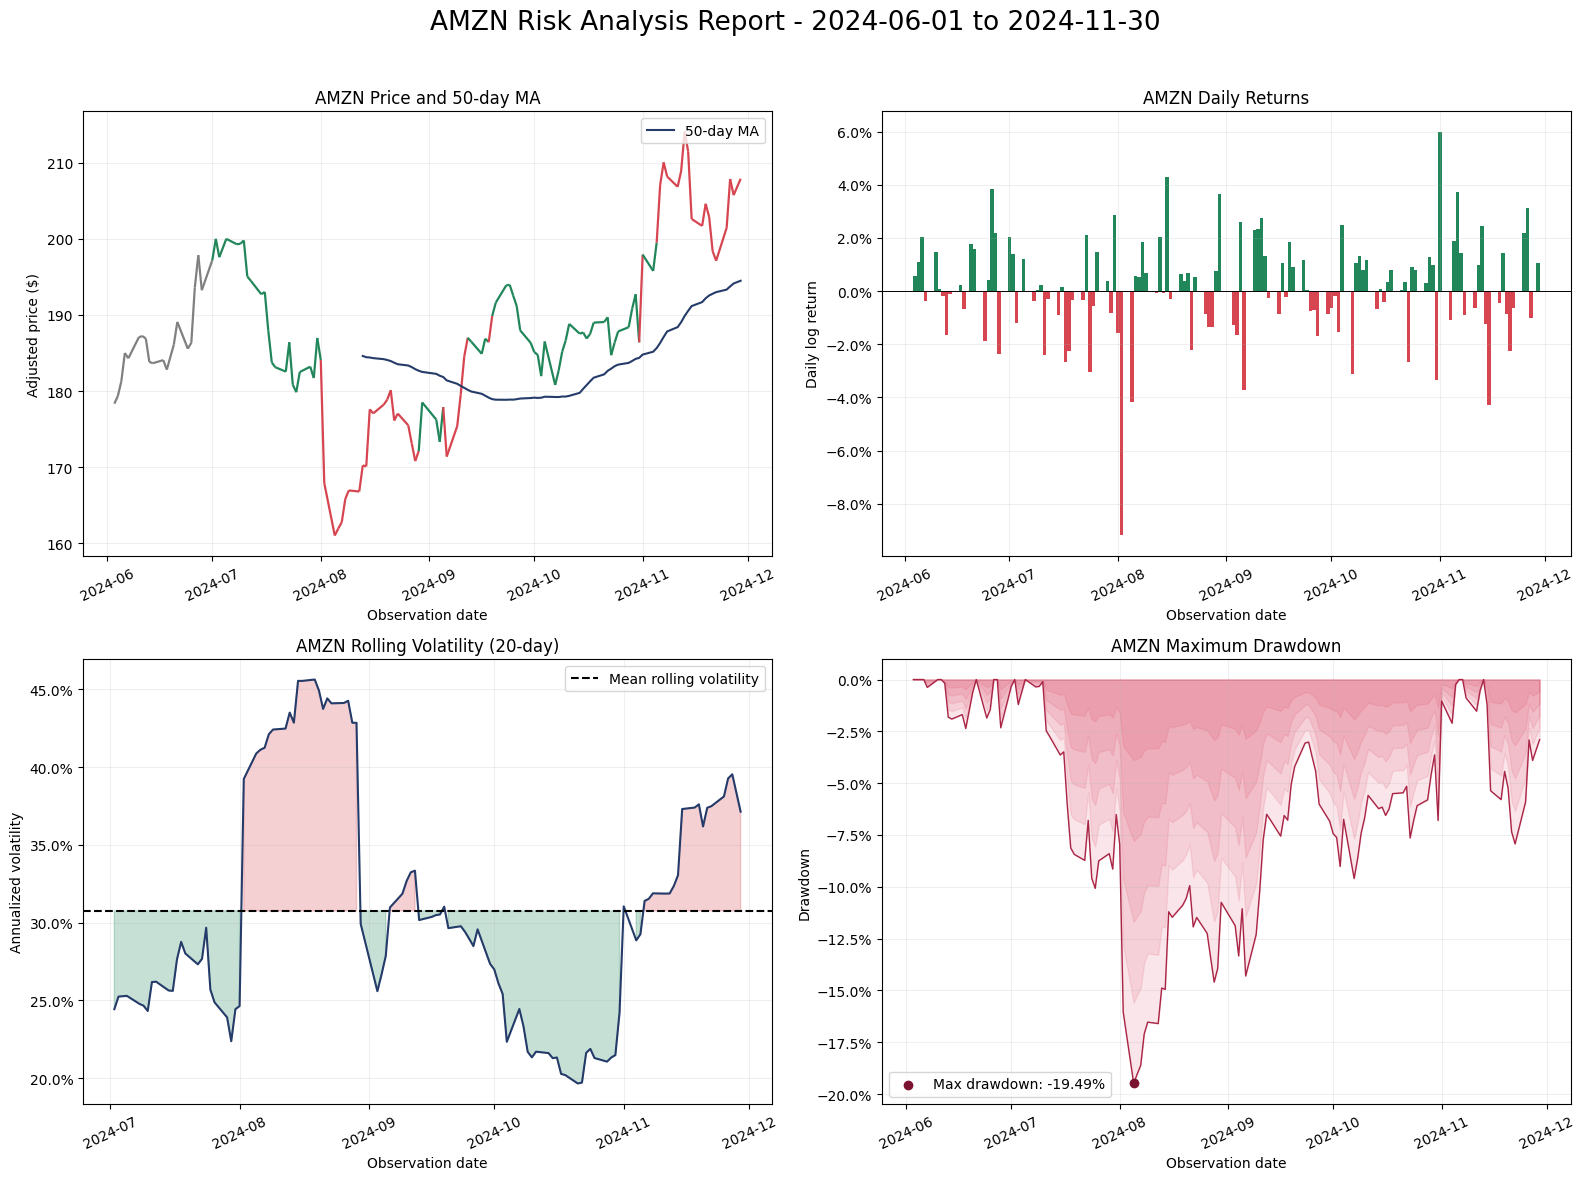

In [4]:
frame["log_return"] = calculate_returns(frame.adj_close)
frame["rolling_volatility"] = calculate_volatility(frame.log_return)
frame["drawdown"] = calculate_max_drawdown(frame.adj_close)
summary = metrics(frame)
display(frame[["adj_close", "log_return", "rolling_volatility", "drawdown"]].tail())
figure = plot_report(frame, ticker, start_date, end_date)
plt.show()
plt.close(figure)

## Summary
Total return is the endpoint price ratio minus one. Annualized return compounds log returns using 252/n. Whole-period annualized volatility differs from the mean rolling volatility used in the portfolio scatter. Best/worst days and up/down averages are log returns. Positive days include zero-return days in the denominator; empty subsets show N/A.

In [5]:
labels = {"total_return": "Total Return", "annualized_return": "Annualized Return",
          "annualized_volatility": "Annualized Volatility", "sharpe_ratio": "Sharpe Ratio",
          "max_drawdown": "Maximum Drawdown", "best_day": "Best Day", "worst_day": "Worst Day",
          "positive_days": "Positive Days", "average_up_day": "Average Up Day", "average_down_day": "Average Down Day"}
rows = []
for key, label in labels.items():
    value = summary[key]
    formatted = "N/A" if not np.isfinite(value) else (f"{value:.2f}" if key == "sharpe_ratio" else f"{value:+.2%}")
    rows.append({"Metric": label, "Value": formatted})
display(pd.DataFrame(rows).set_index("Metric"))

,Value
Metric,
Total Return,+16.57%
Annualized Return,+36.22%
Annualized Volatility,+30.83%
Sharpe Ratio,0.94
Maximum Drawdown,-19.49%
Best Day,+6.00%
Worst Day,-9.19%
Positive Days,+54.40%
Average Up Day,+1.43%


In [6]:
# Named machine-readable result collected only after successful execution.
output = {key: (float(value) if np.isfinite(value) else None) for key, value in summary.items()}
output.update(ticker=ticker, actual_start=str(frame.index.min().date()),
              actual_end=str(frame.index.max().date()), observations=len(frame))
print("HW2_SUMMARY=" + json.dumps(output, allow_nan=False))

HW2_SUMMARY={"total_return": 0.16569474038353693, "annualized_return": 0.3621816678083951, "annualized_volatility": 0.30834250019375653, "sharpe_ratio": 0.9375534730702352, "max_drawdown": -0.19489999999999996, "best_day": 0.06001853058115288, "worst_day": -0.09194755596113545, "positive_days": 0.544, "average_up_day": 0.014252717645535122, "average_down_day": -0.014313465735861376, "avg_daily_return": 0.001226538023618318, "avg_volatility": 0.3075094525961015, "ticker": "AMZN", "actual_start": "2024-06-03", "actual_end": "2024-11-29", "observations": 126}
